In [1]:
import pandas as pd
import os
import cv2
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from tqdm.notebook import tqdm

from sklearn.utils import shuffle
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    RocCurveDisplay,
    confusion_matrix,
    roc_curve,
    auc
)
from sklearn.preprocessing import LabelBinarizer, LabelEncoder, label_binarize
from sklearn.model_selection import GridSearchCV, train_test_split

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model, Sequential, save_model
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    BatchNormalization,
    Input
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import (
    ReduceLROnPlateau,
    EarlyStopping,
    ModelCheckpoint
)

from tensorflow.keras.applications import (
    VGG16,
    ResNet50,
    MobileNetV2,
    EfficientNetB0
)

In [4]:
# Load CSV files
train_labels = pd.read_csv("/kaggle/input/datasets/shuvoalok/raf-db-dataset/train_labels.csv")
test_labels = pd.read_csv("/kaggle/input/datasets/shuvoalok/raf-db-dataset/test_labels.csv")
# Display first 5 rows
print(train_labels.head())

                     image  label
0  train_00001_aligned.jpg      5
1  train_00002_aligned.jpg      5
2  train_00003_aligned.jpg      4
3  train_00004_aligned.jpg      4
4  train_00005_aligned.jpg      5


In [5]:
# Emotion classes
classes = ["surprise", "fear", "disgust", "happy", "sad", "angry", "neutral"]

In [6]:
# Create label mapping
label_map = {label: idx + 1 for idx, label in enumerate(classes)}

In [7]:
# Print label mapping
print(label_map)

{'surprise': 1, 'fear': 2, 'disgust': 3, 'happy': 4, 'sad': 5, 'angry': 6, 'neutral': 7}


In [8]:
#Load the dataset
def load_data(dataset_dir, label_map):
    images = []
    labels = []

    for label, idx in tqdm(label_map.items()):
        folder_path = os.path.join(dataset_dir, str(idx))

        for filename in os.listdir(folder_path):
            img_path = os.path.join(folder_path, filename)

            img = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            images.append(img_rgb)
            labels.append(idx)

    return np.array(images), np.array(labels)

In [9]:
#Load training and testing data
train_images, train_labels = load_data(
    "/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/train",
    label_map
)

test_images, test_labels = load_data(
    "/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test",
    label_map
)

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

In [11]:
#. Count the labels
train_label_counts = Counter(train_labels)
test_label_counts = Counter(test_labels)

train_classes = sorted(train_label_counts.keys())
train_counts = [train_label_counts[cls] for cls in train_classes]

test_classes = sorted(test_label_counts.keys())
test_counts = [test_label_counts[cls] for cls in test_classes]

In [12]:
#Calculate percentages
total_train = sum(train_counts)
total_test = sum(test_counts)


train_percentages = [
    (count / total_train) * 100
    for count in train_counts
]

test_percentages = [
    (count / total_test) * 100
    for count in test_counts
]

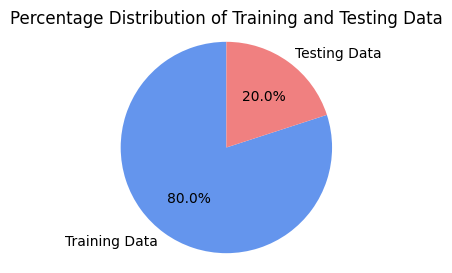

In [13]:
#Pie Chart
labels = ['Training Data', 'Testing Data']

sizes = [total_train, total_test]

colors = ['cornflowerblue', 'lightcoral']

plt.figure(figsize=(3, 3))

plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors
)

plt.title('Percentage Distribution of Training and Testing Data')

plt.axis('equal')

plt.show()

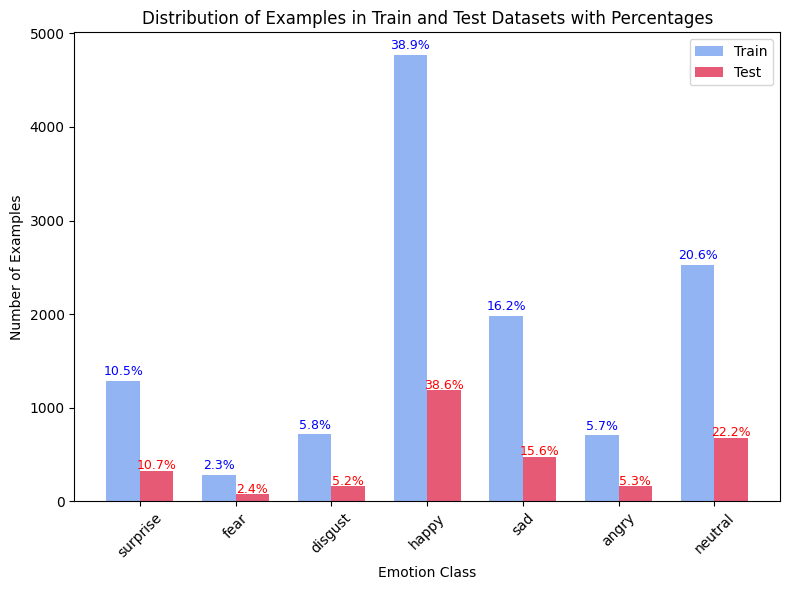

In [14]:
#Bar Chart
plt.figure(figsize=(8, 6))

x = range(len(classes))
bar_width = 0.35

plt.bar(
    x,
    train_counts,
    width=bar_width,
    label='Train',
    alpha=0.7,
    color='cornflowerblue'
)

plt.bar(
    [p + bar_width for p in x],
    test_counts,
    width=bar_width,
    label='Test',
    alpha=0.7,
    color='crimson'
)

for i, (train_count, test_count) in enumerate(zip(train_counts, test_counts)):

    plt.text(
        i,
        train_count + 0.005 * total_train,
        f'{train_percentages[i]:.1f}%',
        ha='center',
        color='blue',
        fontsize=9
    )

    plt.text(
        i + bar_width,
        test_count + 0.005 * total_test,
        f'{test_percentages[i]:.1f}%',
        ha='center',
        color='red',
        fontsize=9
    )

plt.xticks(
    [p + bar_width / 2 for p in x],
    classes,
    rotation=45
)

plt.xlabel("Emotion Class")
plt.ylabel("Number of Examples")
plt.title("Distribution of Examples in Train and Test Datasets with Percentages")

plt.legend()

plt.tight_layout()

plt.show()

In [15]:
#Concatenate Training and Test Data
X_train = np.concatenate([train_images, test_images], axis=0)
Y_train = np.concatenate([train_labels, test_labels], axis=0)

In [16]:
#Check the Shape of the Dataset
X_train = np.concatenate([train_images, test_images], axis=0)
Y_train = np.concatenate([train_labels, test_labels], axis=0)

print(X_train.shape)
print(Y_train.shape)

(15339, 100, 100, 3)
(15339,)


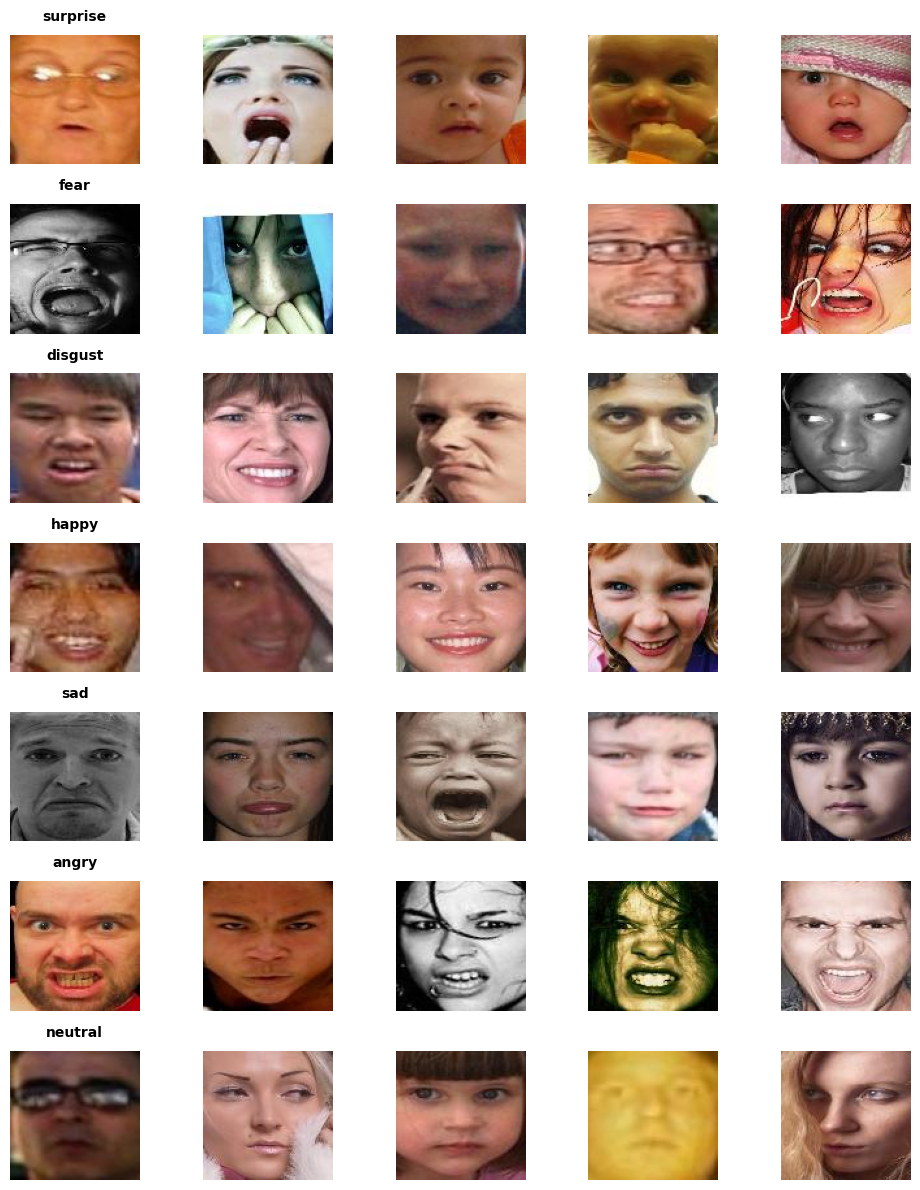

In [17]:
#Display Random Sample Images from Each Class
def show_examples(train_images, train_labels, labels, num_examples=5):
    num_classes = len(classes)
    fig, axs = plt.subplots(num_classes, num_examples, figsize=(10, 12))

    for i, class_name in enumerate(classes):
        class_indices = [idx for idx, label in enumerate(train_labels) if label == i + 1]
        selected_indices = np.random.choice(class_indices, num_examples, replace=False)

        axs[i, 0].set_title(class_name, fontsize=10, pad=10, fontweight='bold')

        # Display the random images for the current class
        for j, idx in enumerate(selected_indices):
            img = train_images[idx]
            axs[i, j].imshow(img)
            axs[i, j].axis('off')

    plt.tight_layout()
    plt.show()

show_examples(X_train, Y_train, classes)

In [18]:
#Find the Most Frequent Image Shapes
train_data_shapes = []

for img in X_train:
    train_data_shapes.append(img.shape)

shape_counts = {}

for shape in train_data_shapes:
    if shape not in shape_counts:
        shape_counts[shape] = 0
    shape_counts[shape] += 1

sorted_shapes = sorted(shape_counts.items(), key=lambda x: x[1], reverse=True)

print("Most frequent Train images shapes:")

for shape, count in sorted_shapes[:3]:
    print(f"- {shape}: {count}")

Most frequent Train images shapes:
- (100, 100, 3): 15339


In [19]:
#Plot Class Distribution
from collections import Counter

def plot_class_distribution(y, title):
    train_label_counts_resampled = Counter(y)

    train_classes_resampled = sorted(train_label_counts_resampled.keys())
    train_counts_resampled = [
        train_label_counts_resampled[cls]
        for cls in train_classes_resampled
    ]

    plt.figure(figsize=(6, 3))

    x_labels = ['Surprise', 'Fear', 'Disgust', 'Happy', 'Sad', 'Angry', 'Neutral']

    plt.bar(x_labels, train_counts_resampled, color="steelblue")

    plt.xlabel("Emotion Class")
    plt.ylabel("Number of Examples")
    plt.title(title)

    plt.tight_layout()
    plt.show()

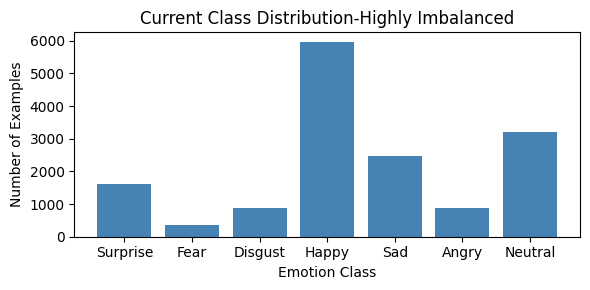

In [20]:
#Plot Current (Imbalanced) Dataset
plot_class_distribution(
    Y_train,
    "Current Class Distribution-Highly Imbalanced"
)

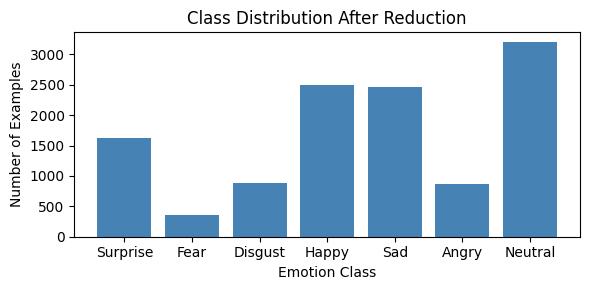

In [21]:
import numpy as np

# Function to reduce the majority class safely
def reduce_class(X, y, target_class, target_size):

    # Get indices for the target class
    class_indices = np.where(y == target_class)[0]

    # Get indices for all other classes
    non_class_indices = np.where(y != target_class)[0]

    # If target_size is larger than available images,
    # automatically use all available images
    if target_size > len(class_indices):
        print(f"Warning: Class {target_class} has only {len(class_indices)} images.")
        print(f"Using {len(class_indices)} images instead of {target_size}.")
        target_size = len(class_indices)

    # Randomly choose images
    reduced_class_indices = np.random.choice(
        class_indices,
        size=target_size,
        replace=False
    )

    # Combine selected images with all other classes
    final_indices = np.concatenate(
        [reduced_class_indices, non_class_indices]
    )

    # Shuffle indices
    np.random.shuffle(final_indices)

    X_reduced = X[final_indices]
    y_reduced = y[final_indices]

    return X_reduced, y_reduced


# --------------------------------------------
# Reduce Class 4 (Happy)
# --------------------------------------------

target_class = 4
target_size = 2500     # Must be <= 2613 for your dataset

X_train_reduced, y_train_reduced = reduce_class(
    X_train,
    Y_train,
    target_class,
    target_size
)

# --------------------------------------------
# Plot new class distribution
# --------------------------------------------

plot_class_distribution(
    y_train_reduced,
    "Class Distribution After Reduction"
)

In [22]:
#Data Augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

def augment_classes(images, labels, target_counts):

    # Initialize the image augmentation generator
    datagen = ImageDataGenerator(
        rotation_range=10,
        width_shift_range=0.1,
        height_shift_range=0.1,
        zoom_range=0.1,
        vertical_flip=False,
        horizontal_flip=True,
        channel_shift_range=50.0,
        fill_mode='nearest'
    )

    augmented_images = images.copy()
    augmented_labels = labels.copy()

    for target_class, target_count in target_counts.items():

        class_images = images[labels == target_class]
        class_labels = labels[labels == target_class]

        augment_count = target_count - len(class_images)

        if augment_count > 0:

            print(
                f'Class {target_class}: {len(class_images)} original samples, '
                f'augmenting with {augment_count} new samples.'
            )

            class_images_augmented = []
            class_labels_augmented = []

            for batch in datagen.flow(
                class_images,
                batch_size=1,
                seed=42
            ):
                aug_image = batch[0].astype(np.uint8)

                class_images_augmented.append(aug_image)
                class_labels_augmented.append(target_class)

                if len(class_images_augmented) >= augment_count:
                    break

            augmented_images = np.vstack((
                augmented_images,
                np.array(class_images_augmented)
            ))

            augmented_labels = np.hstack((
                augmented_labels,
                np.array(class_labels_augmented)
            ))

    return augmented_images, augmented_labels

In [23]:
#Augment the Dataset
# Example usage

target_counts = {
    1: 3500,
    2: 3500,
    3: 3500,
    5: 3500,
    6: 3500,
    7: 3500
}

X_train_augmented, y_train_augmented = augment_classes(
    X_train_reduced,
    y_train_reduced,
    target_counts
)

Class 1: 1619 original samples, augmenting with 1881 new samples.
Class 2: 355 original samples, augmenting with 3145 new samples.
Class 3: 877 original samples, augmenting with 2623 new samples.
Class 5: 2460 original samples, augmenting with 1040 new samples.
Class 6: 867 original samples, augmenting with 2633 new samples.
Class 7: 3204 original samples, augmenting with 296 new samples.


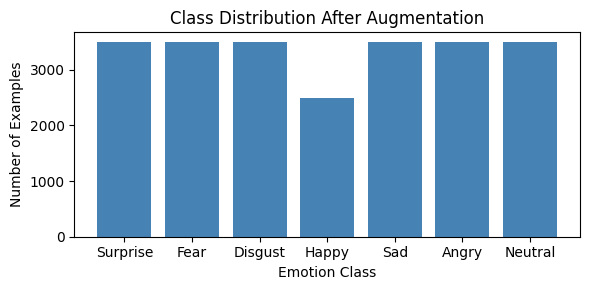

In [24]:
#Plot Distribution After Augmentation
plot_class_distribution(
    y_train_augmented,
    "Class Distribution After Augmentation"
)

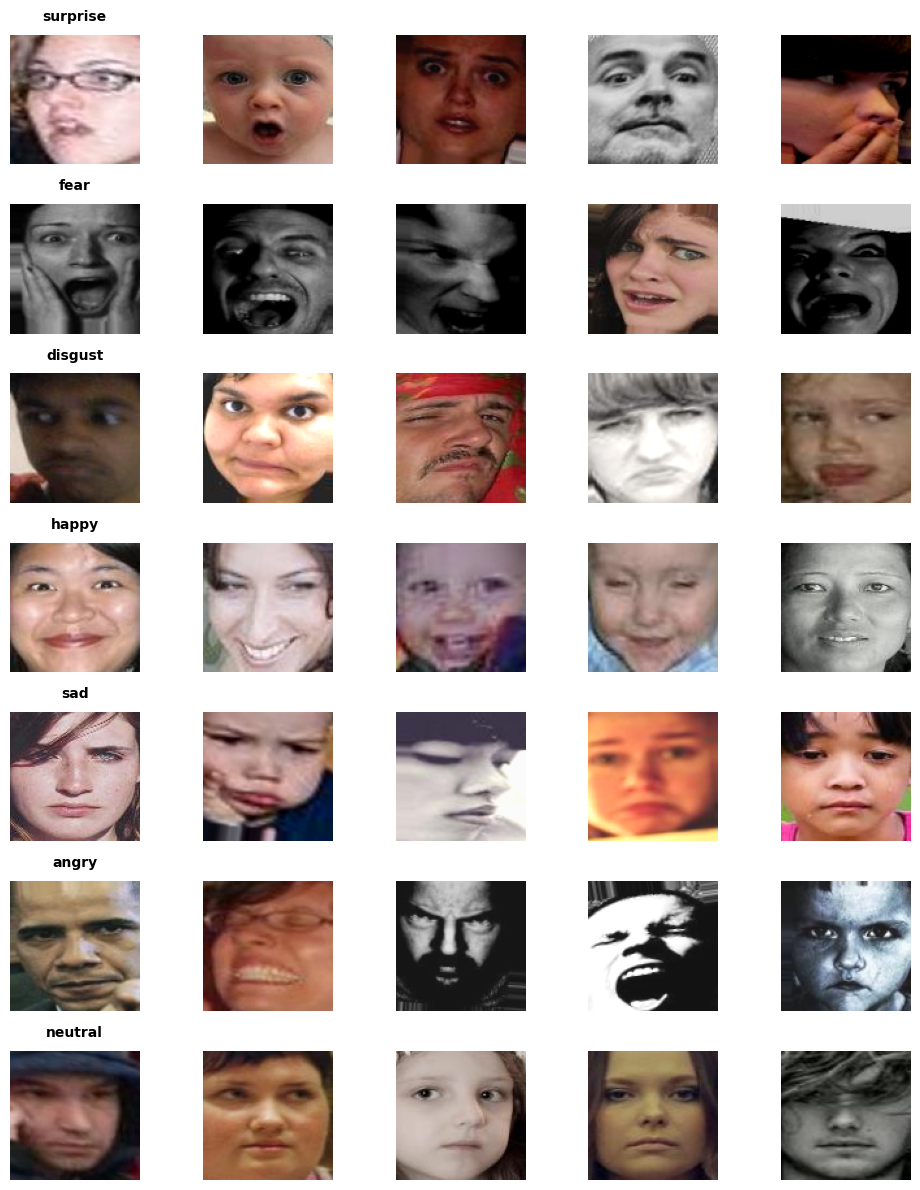

In [25]:
#Display Augmented Images
show_examples(
    X_train_augmented,
    y_train_augmented,
    classes
)

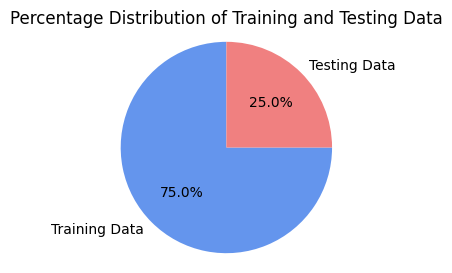

In [26]:
#Split the Dataset into Training and Testing Sets
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X_train_augmented,
    y_train_augmented,
    test_size=0.25,
    shuffle=True,
    random_state=42
)

total_images = len(X_train) + len(X_test)

train_percentage = (len(X_train) / total_images) * 100
test_percentage = (len(X_test) / total_images) * 100

labels = ['Training Data', 'Testing Data']
sizes = [train_percentage, test_percentage]
colors = ['cornflowerblue', 'lightcoral']

plt.figure(figsize=(3, 3))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors
)
plt.title('Percentage Distribution of Training and Testing Data')
plt.axis('equal')
plt.show()

In [27]:
#Normalize Images
def normalize_images(images):
    return images / 255.0

train_images_normalized = normalize_images(X_train)
test_images_normalized = normalize_images(X_test)

In [28]:
#Reshape Images
def reshape_images(images):
    return images.reshape((images.shape[0], 100, 100, 3))

train_images_reshaped = reshape_images(train_images_normalized)
test_images_reshaped = reshape_images(test_images_normalized)

print(f"Training images shape: {train_images_reshaped.shape}")
print(f"Testing images shape: {test_images_reshaped.shape}")

Training images shape: (17625, 100, 100, 3)
Testing images shape: (5875, 100, 100, 3)


In [29]:
#One-Hot Encode Labels
from tensorflow.keras.utils import to_categorical

Y_train_cat = to_categorical(
    Y_train - 1,
    num_classes=len(classes)
)

Y_test_cat = to_categorical(
    Y_test - 1,
    num_classes=len(classes)
)

In [30]:
#Create Data Generator
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    vertical_flip=False,
    horizontal_flip=True,
    fill_mode='nearest'
)

train_generator = datagen.flow(
    train_images_reshaped,
    Y_train_cat,
    batch_size=64
)

In [31]:
#Build the CNN Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

cnn_model = Sequential([
    Conv2D(
        32,
        (3, 3),
        activation='relu',
        input_shape=(test_images_reshaped[0].shape)
    ),
    MaxPooling2D((2, 2)),

    Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),
    MaxPooling2D((2, 2)),

    Conv2D(
        128,
        (3, 3),
        activation='relu'
    ),
    MaxPooling2D((2, 2)),

    Conv2D(
        512,
        (3, 3),
        activation='relu'
    ),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(
        512,
        activation='relu'
    ),

    Dropout(0.5),

    Dense(
        len(classes),
        activation='softmax'
    )
])

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-07-10 12:56:01.847301: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 512)      │       590,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         3,591 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,881,991 (18.62 MB)

 Trainable params: 4,881,991 (18.62 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
#
from tensorflow.keras.callbacks import (
    ReduceLROnPlateau,
    EarlyStopping,
    ModelCheckpoint
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_accuracy',
    factor=0.1,
    patience=10,
    min_delta=0.0001,
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath='best_CNNModel.keras',
    monitor='val_accuracy',
    save_best_only=True
)

CNN_History = cnn_model.fit(
    train_generator,
    epochs=10,      # suggested epochs is 60
    batch_size=32,
    validation_data=(test_images_reshaped, Y_test_cat),
    callbacks=[reduce_lr, early_stop, checkpoint]
)

Epoch 1/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 267s 958ms/step - accuracy: 0.2332 - loss: 1.8548 - val_accuracy: 0.3084 - val_loss: 1.7266 - learning_rate: 0.0010
Epoch 2/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 264s 957ms/step - accuracy: 0.3434 - loss: 1.6856 - val_accuracy: 0.4441 - val_loss: 1.4764 - learning_rate: 0.0010
Epoch 3/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 264s 956ms/step - accuracy: 0.4418 - loss: 1.4894 - val_accuracy: 0.5205 - val_loss: 1.2819 - learning_rate: 0.0010
Epoch 4/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 264s 957ms/step - accuracy: 0.4907 - loss: 1.3402 - val_accuracy: 0.5753 - val_loss: 1.1207 - learning_rate: 0.0010
Epoch 5/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 263s 952ms/step - accuracy: 0.5384 - loss: 1.2328 - val_accuracy: 0.5789 - val_loss: 1.1152 - learning_rate: 0.0010
Epoch 6/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 265s 961ms/step - accuracy: 0.5642 - loss: 1.1610 - val_accuracy: 0.6080 - val_loss: 1.0505 - learning_rate: 0.0010
Epoch 7/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 266s 964ms/step - accura

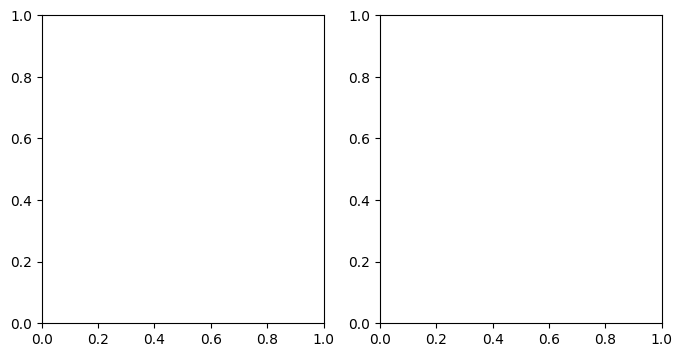

In [33]:
# Get training history
train_loss = CNN_History.history['loss']
val_loss = CNN_History.history['val_loss']

train_accuracy = CNN_History.history['accuracy']
val_accuracy = CNN_History.history['val_accuracy']

# Plot Loss and Accuracy
fig, ax = plt.subplots(1, 2, figsize=(8, 4))

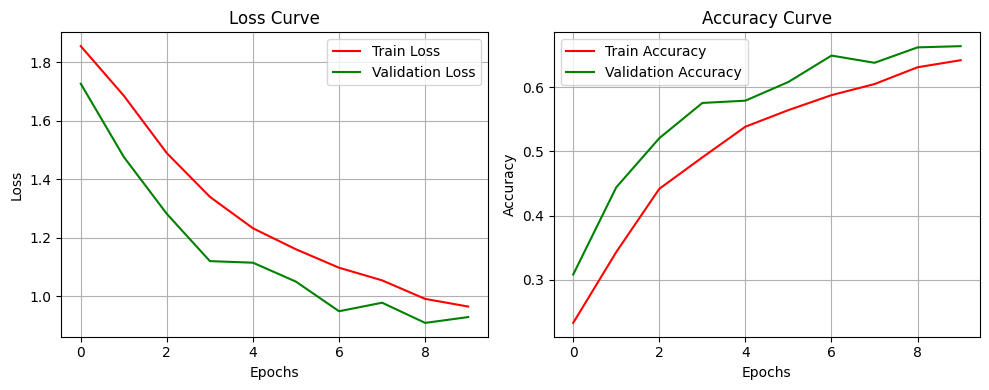

In [34]:
import matplotlib.pyplot as plt

# Get training history
train_loss = CNN_History.history['loss']
val_loss = CNN_History.history['val_loss']
train_accuracy = CNN_History.history['accuracy']
val_accuracy = CNN_History.history['val_accuracy']

# Create plots
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Loss Curve
ax[0].plot(train_loss, 'r', label='Train Loss')
ax[0].plot(val_loss, 'g', label='Validation Loss')
ax[0].set_title('Loss Curve')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid(True)

# Accuracy Curve
ax[1].plot(train_accuracy, 'r', label='Train Accuracy')
ax[1].plot(val_accuracy, 'g', label='Validation Accuracy')
ax[1].set_title('Accuracy Curve')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Accuracy')
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [35]:
train_CNNresult = cnn_model.evaluate(train_images_reshaped, Y_train_cat)
test_CNNresult = cnn_model.evaluate(test_images_reshaped, Y_test_cat)

print("Train Loss: {:.2f}%".format(train_CNNresult[0] * 100))
print("Train Accuracy: {:.2f}%".format(train_CNNresult[1] * 100))

print("\nTest Loss: {:.2f}%".format(test_CNNresult[0] * 100))
print("Test Accuracy: {:.2f}%".format(test_CNNresult[1] * 100))

551/551 ━━━━━━━━━━━━━━━━━━━━ 62s 113ms/step - accuracy: 0.6854 - loss: 0.8366
184/184 ━━━━━━━━━━━━━━━━━━━━ 21s 113ms/step - accuracy: 0.6637 - loss: 0.9295
Train Loss: 83.66%
Train Accuracy: 68.54%

Test Loss: 92.95%
Test Accuracy: 66.37%
